# AlexNet with Tensorgami

Load a model, call `tg.draw` with an example input, and the figure shows inline. Nothing is
written to disk until you call `save`, and the model itself is left untouched. This notebook
shows the options one at a time: level of detail, view, style, direction and layout.

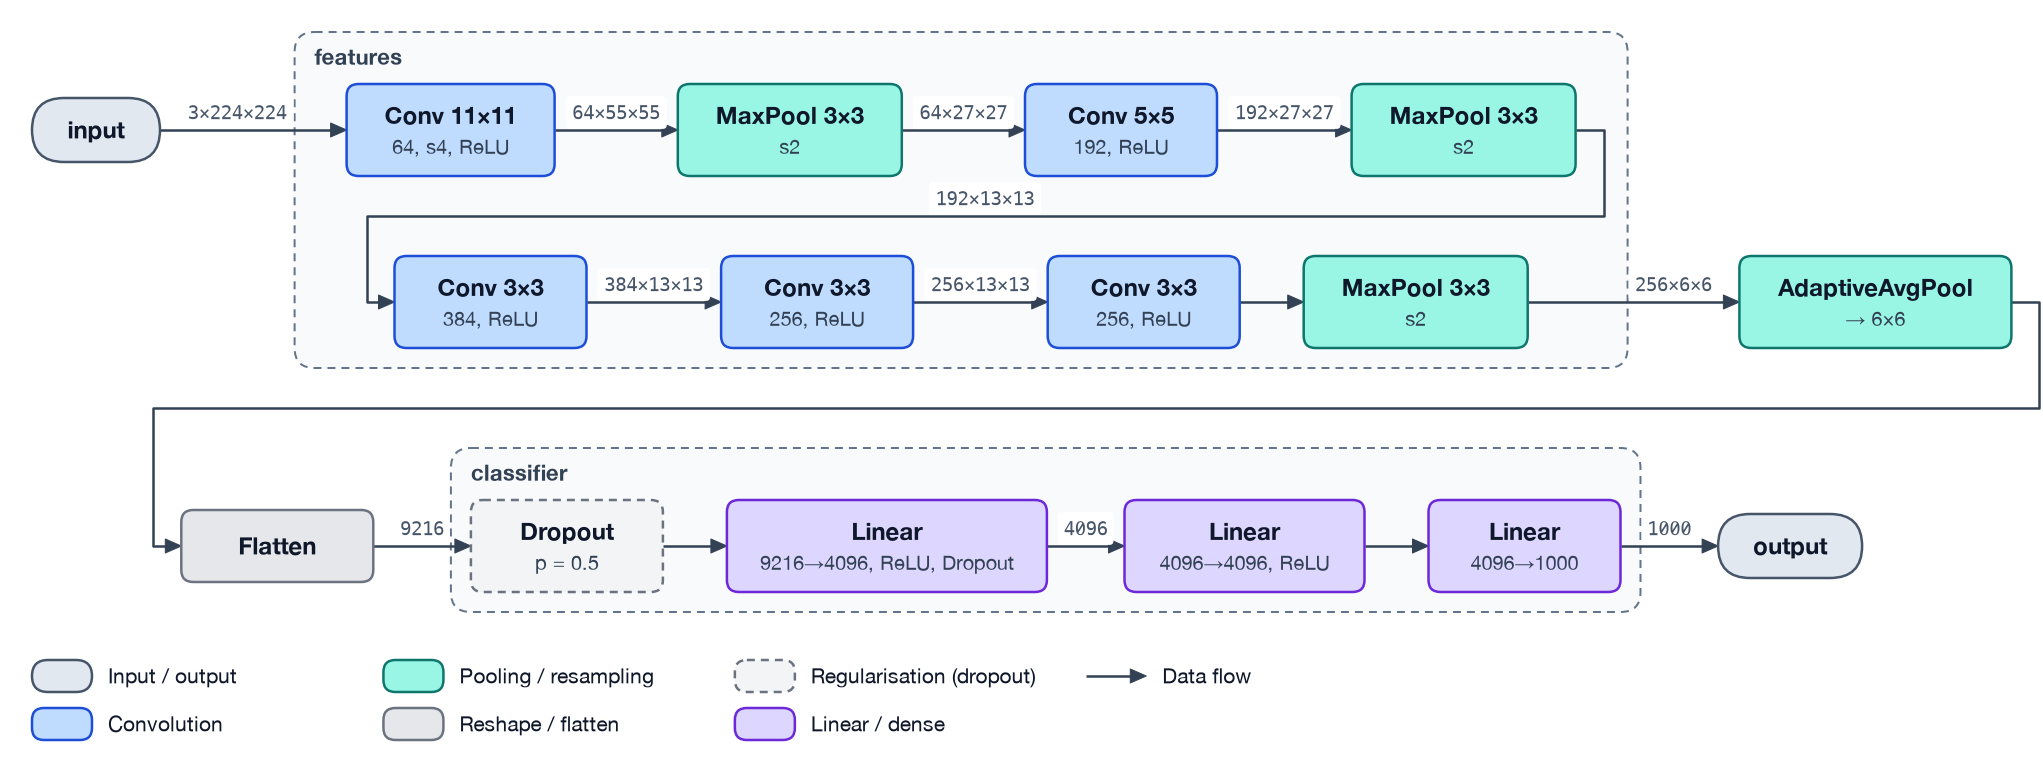

In [1]:
import torch
from alexnet import AlexNet  # examples/alexnet.py: AlexNet as defined in torchvision

import tensorgami as tg

model = AlexNet()
x = torch.randn(1, 3, 224, 224)  # one image, with the batch dimension

tg.draw(model, x)  # layer level, block view, default style

## Level of detail

`level` by number or name: 0 `"system"`, 1 `"stages"` (the model's direct sub-modules),
2 `"layers"` (the default), 3 `"operators"` (everything traced).

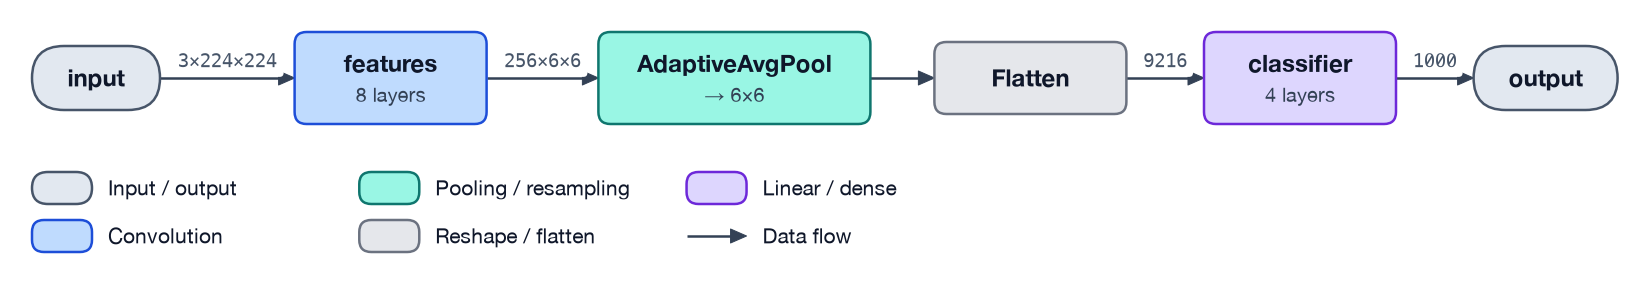

In [2]:
tg.draw(model, x, level="stages")

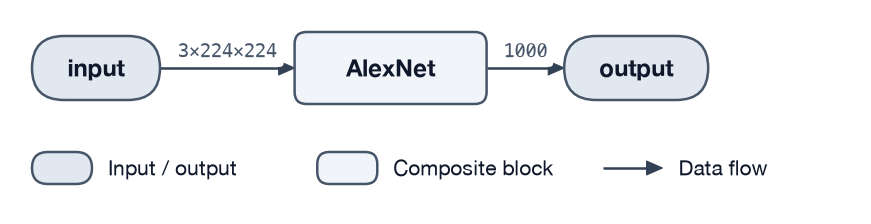

In [3]:
tg.draw(model, x, level="system")

## Views

`view="volume"` draws every layer as the tensor it produces (C × H × W), as in the original
paper; the dense layers are thin bars. (`view="unrolled"` is for recurrent models, see
`tour.ipynb`.)

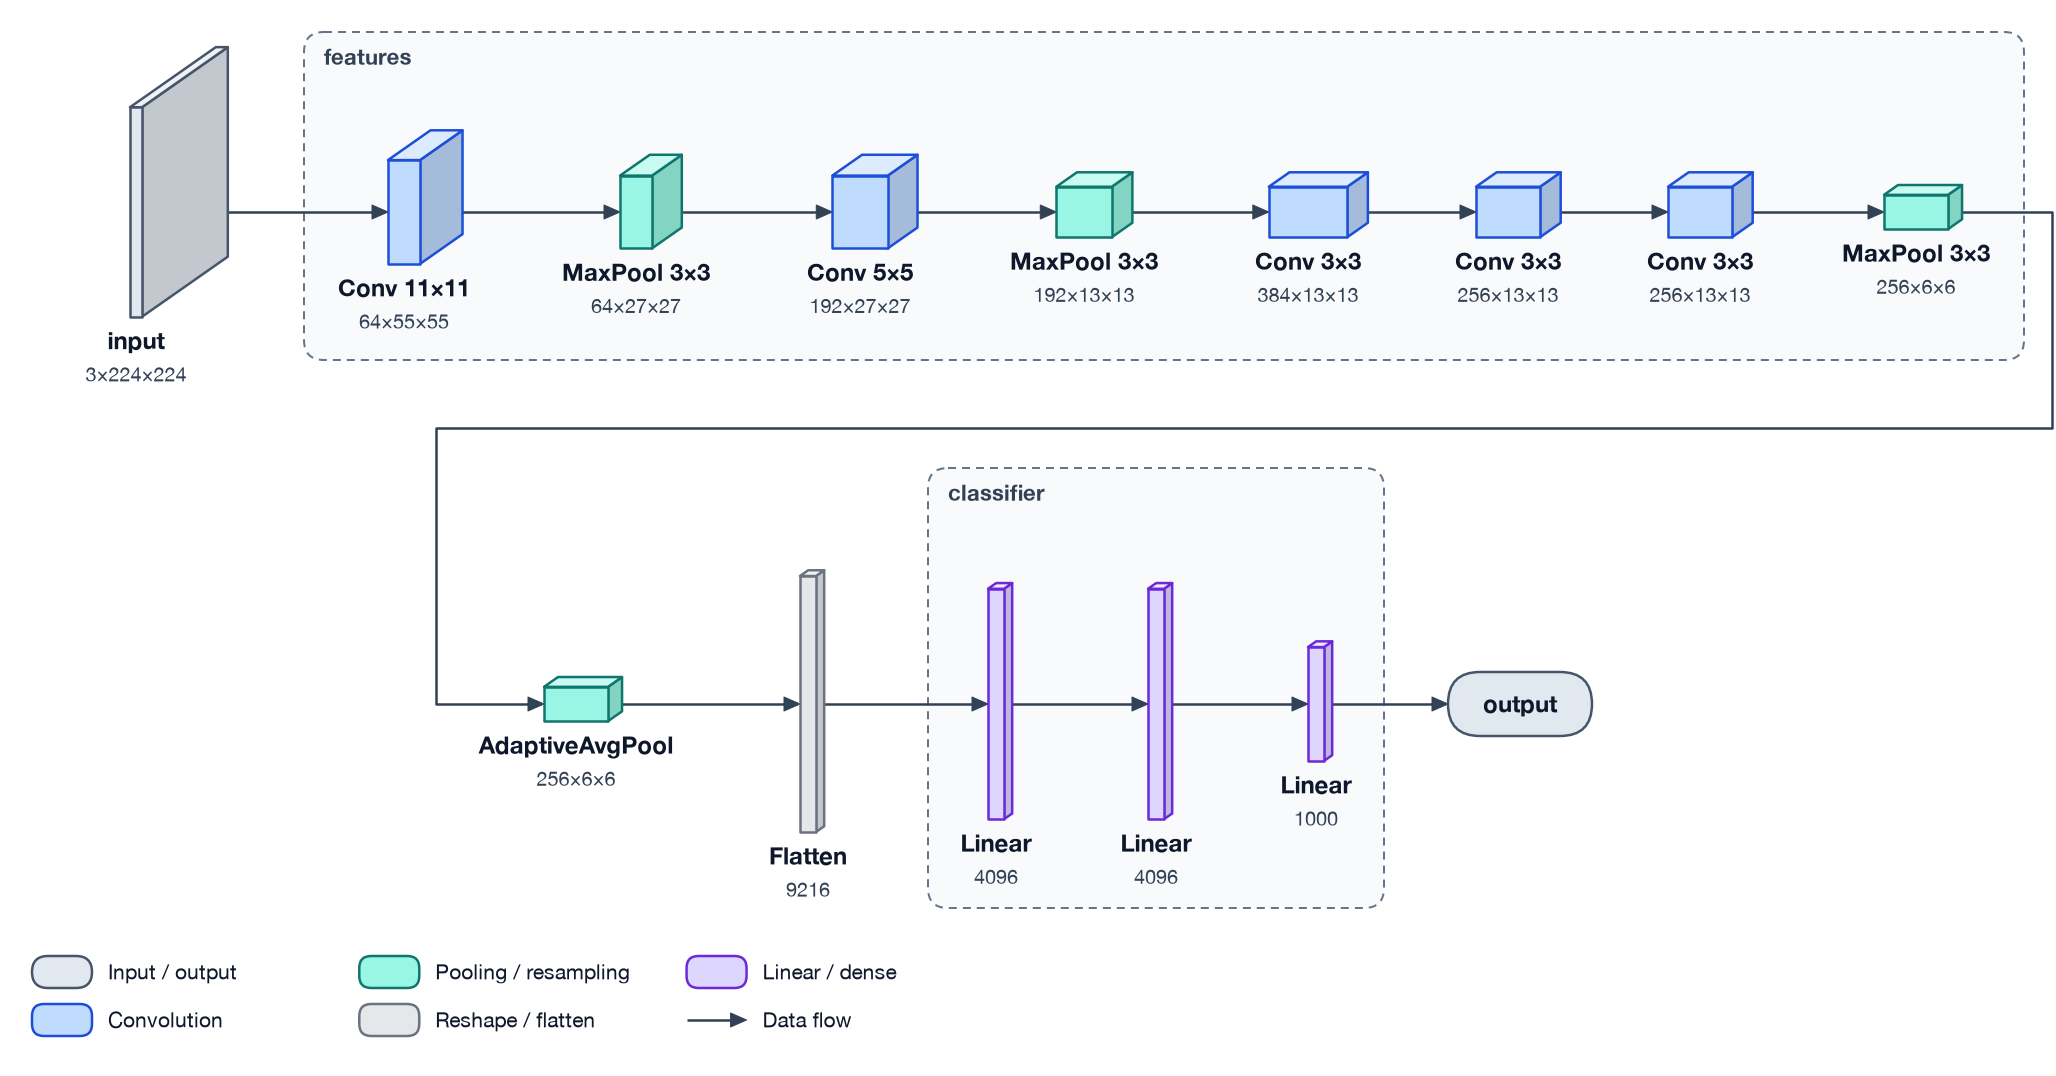

In [4]:
tg.draw(model, x, view="volume")

## Styles

`style="default"`, `"origami"` (upright cards left → right), `"origami-extended"` (flat cards,
top → bottom), `"etching"` (black ink, operations told apart by engraved textures: for
black-and-white print), or the path of your own `.toml` style.

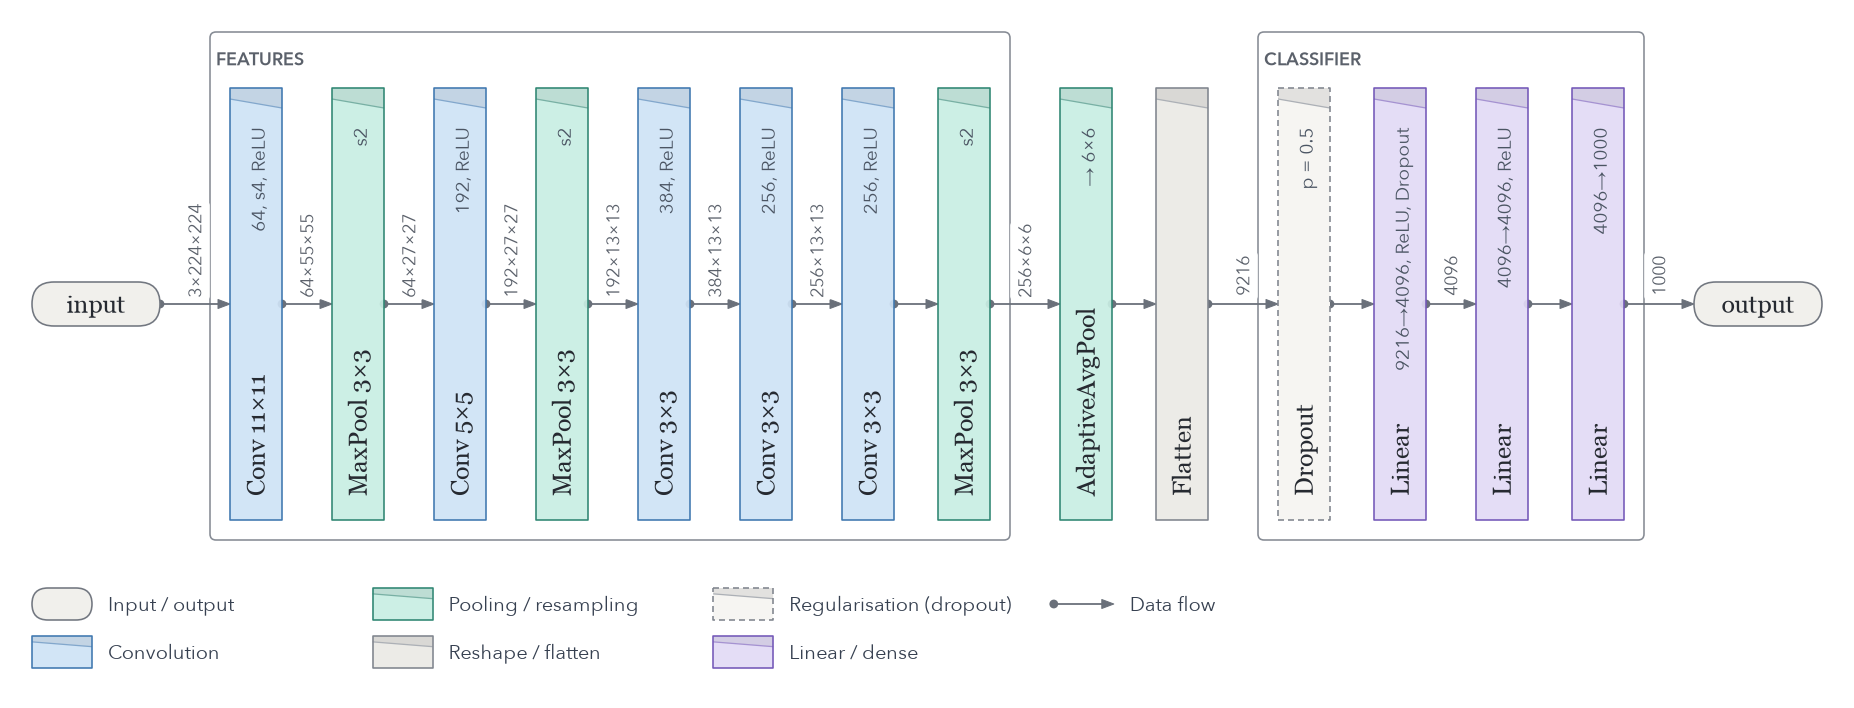

In [5]:
tg.draw(model, x, style="origami")

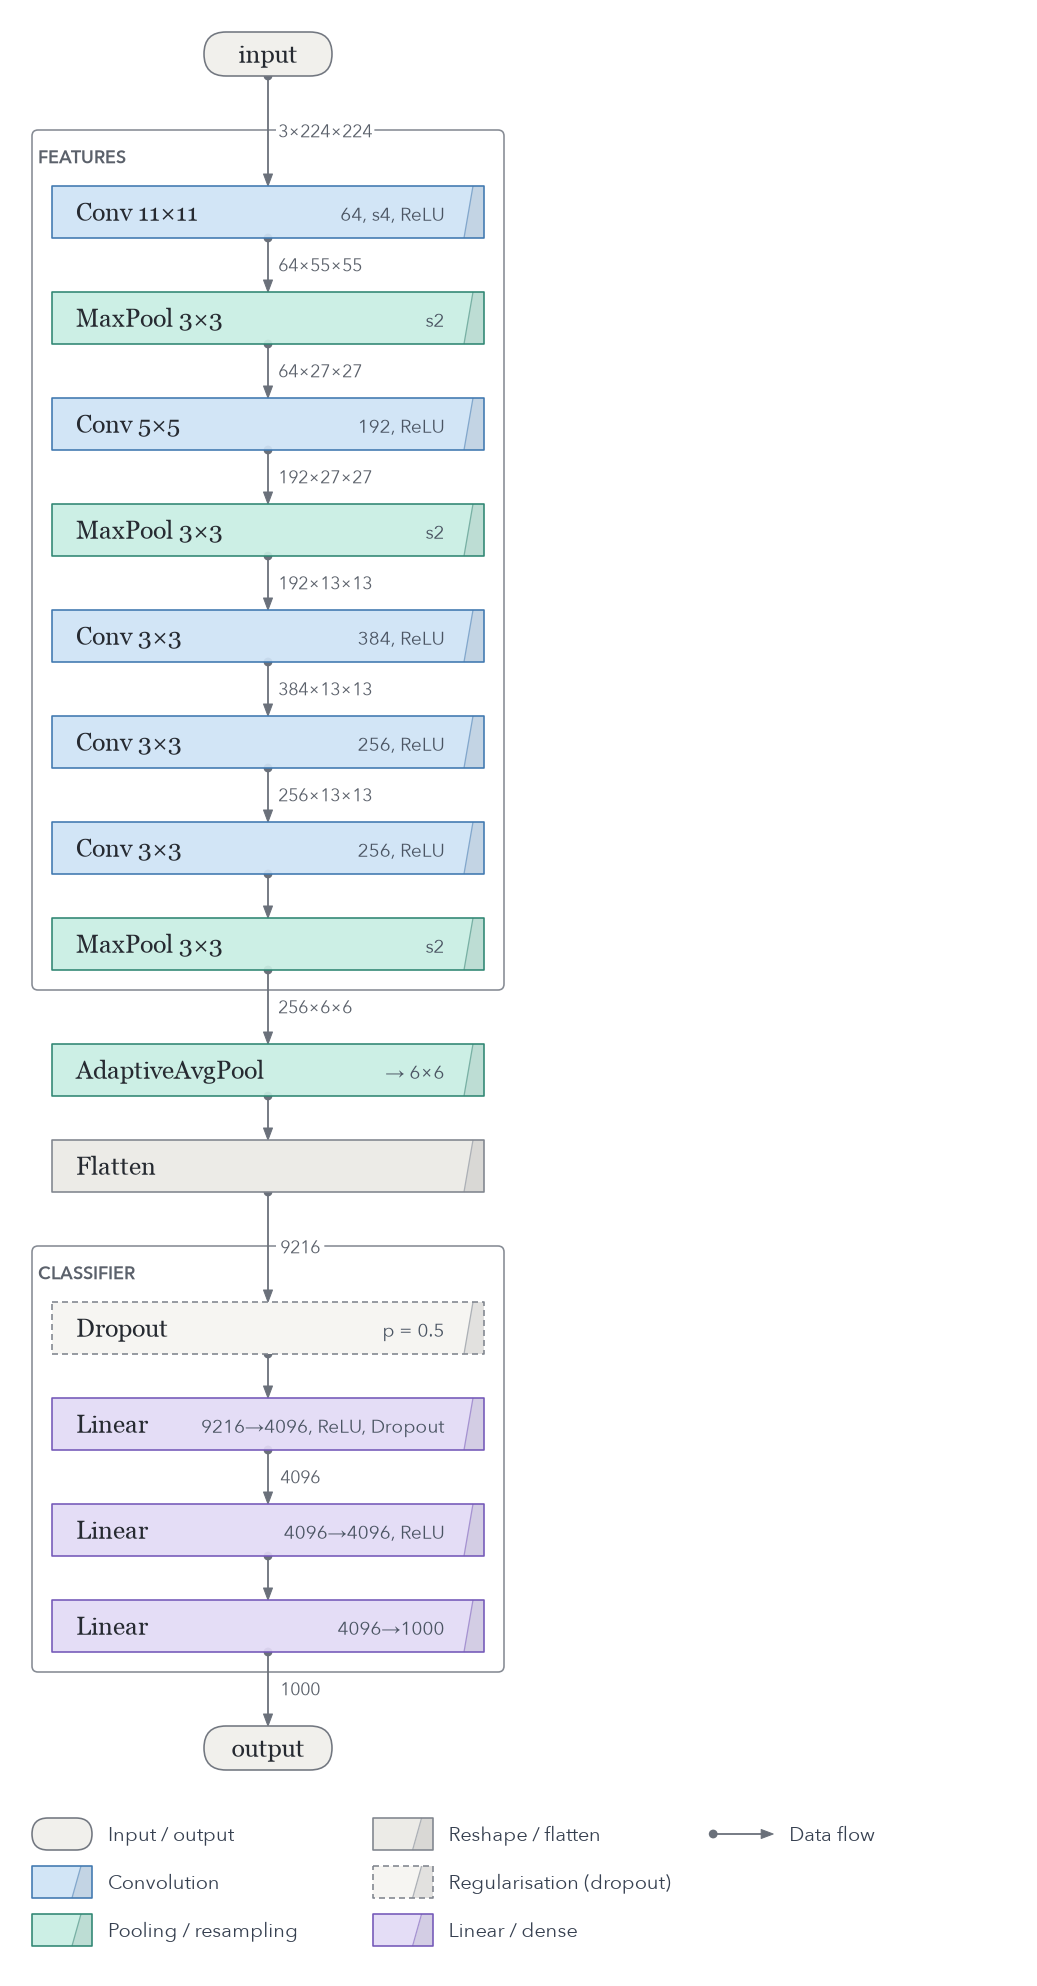

In [6]:
tg.draw(model, x, style="origami-extended")

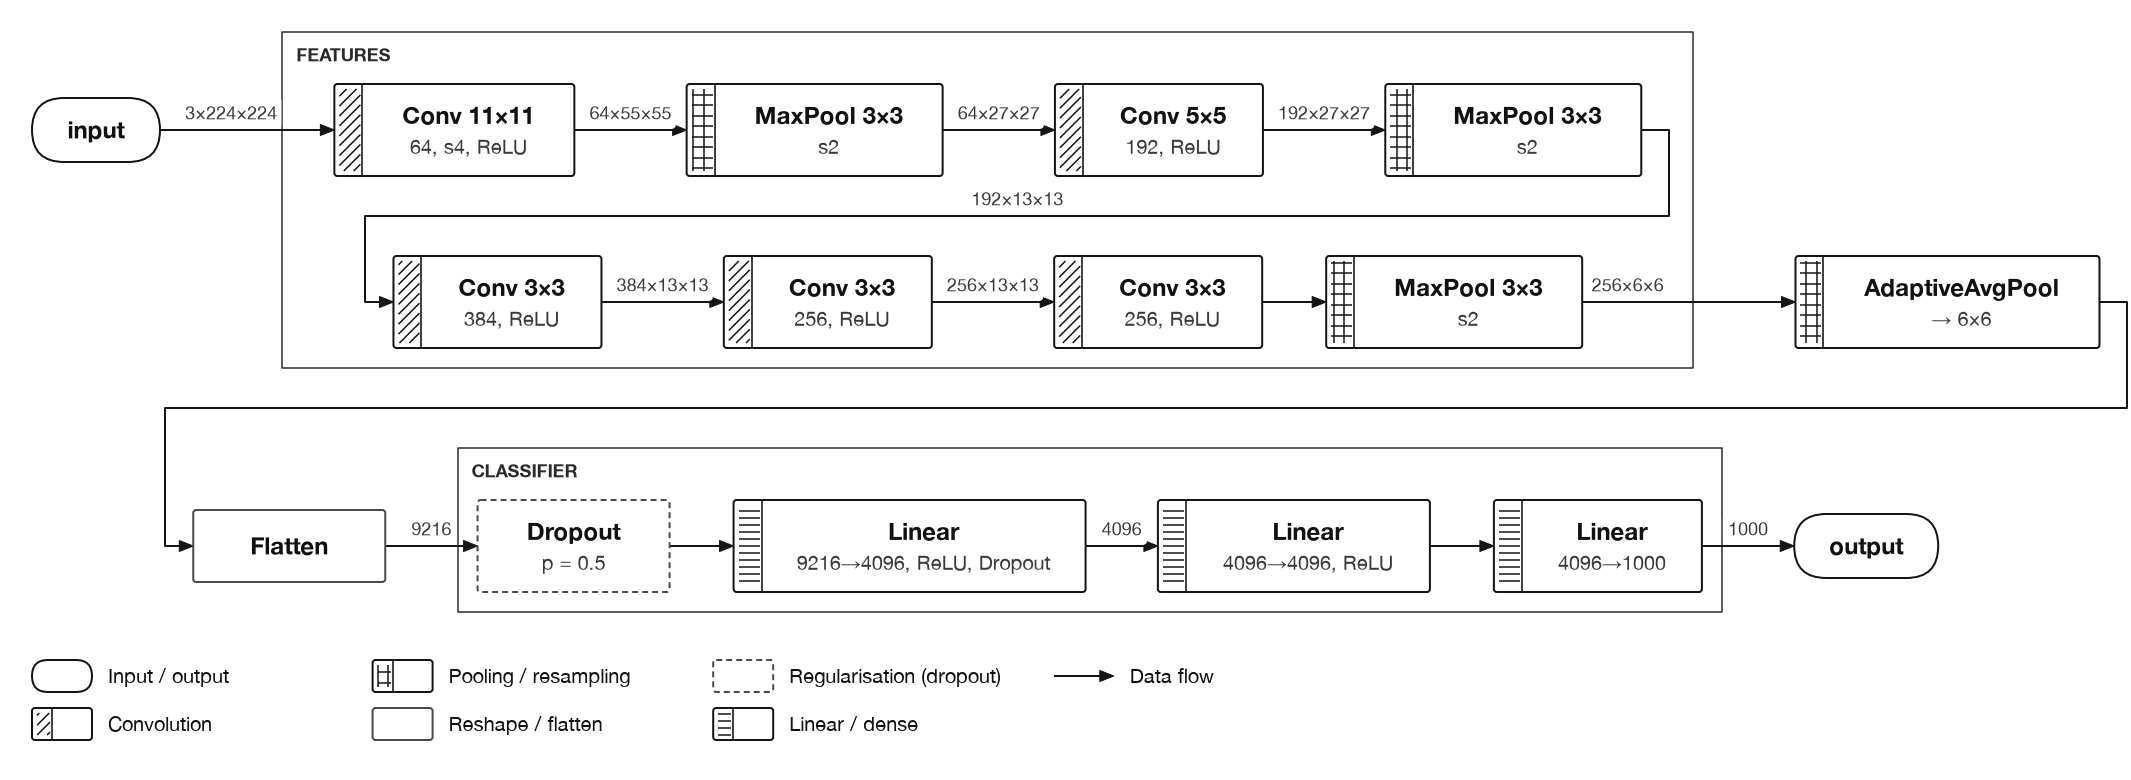

In [7]:
tg.draw(model, x, style="etching")

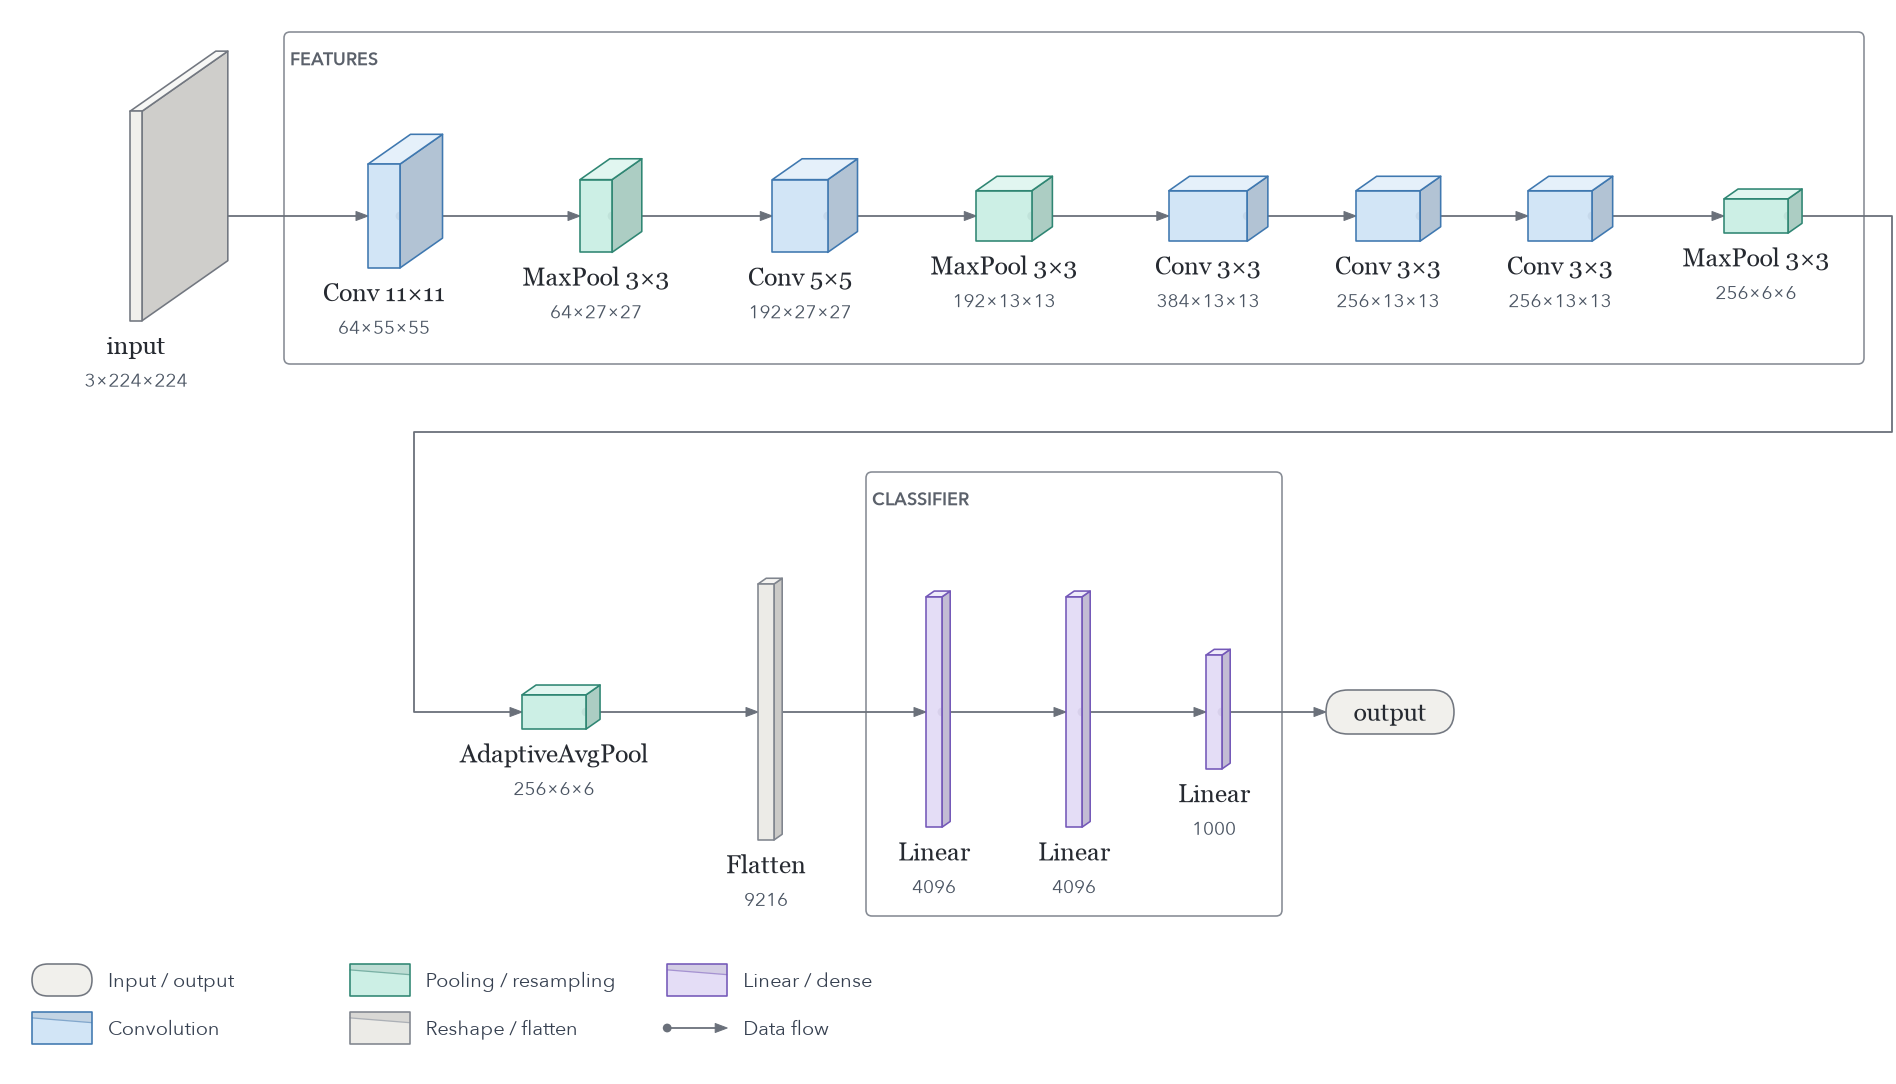

In [8]:
tg.draw(model, x, style="origami", view="volume")

## Direction and layout options

`direction="TB"` runs top → bottom; any layout option can be passed by name, e.g.
`legend=False`, `wrap_width=None` (keep one row) or `shapes_on_edges=False`.

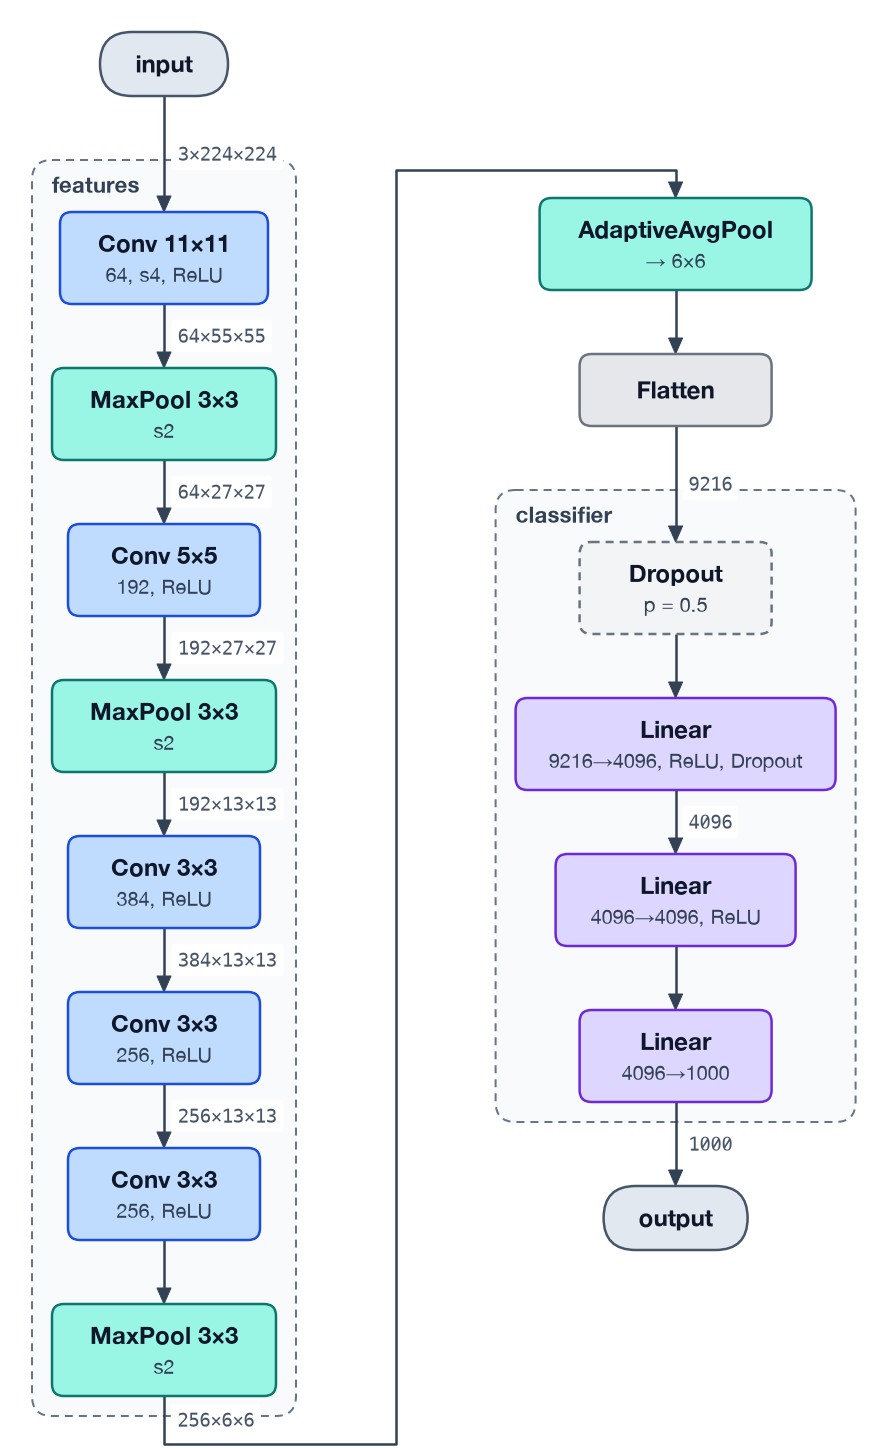

In [9]:
tg.draw(model, x, direction="TB", legend=False)

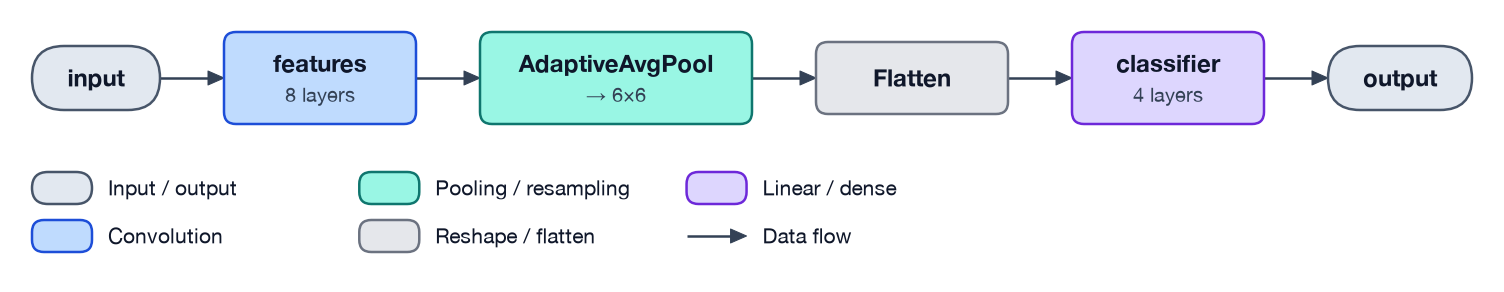

In [10]:
tg.draw(model, x, level="stages", wrap_width=None, shapes_on_edges=False)

## Slides

`fit="slide"` makes a figure for a 16:9 slide: larger text and lines, and the layout
whose text is largest once the figure fills the slide, centred on the slide's
proportions. Saved, it is 13.33 × 7.5 in, the slide size of PowerPoint, Keynote and
Google Slides (`fig.save("alexnet.png", dpi=144)`: 1920 × 1080 px). The figure says how
large its box names are on the slide.

<tensorgami.Figure 'AlexNet' 1075×605 px, style 'default, slide', slide 16:9, box names 14 pt>


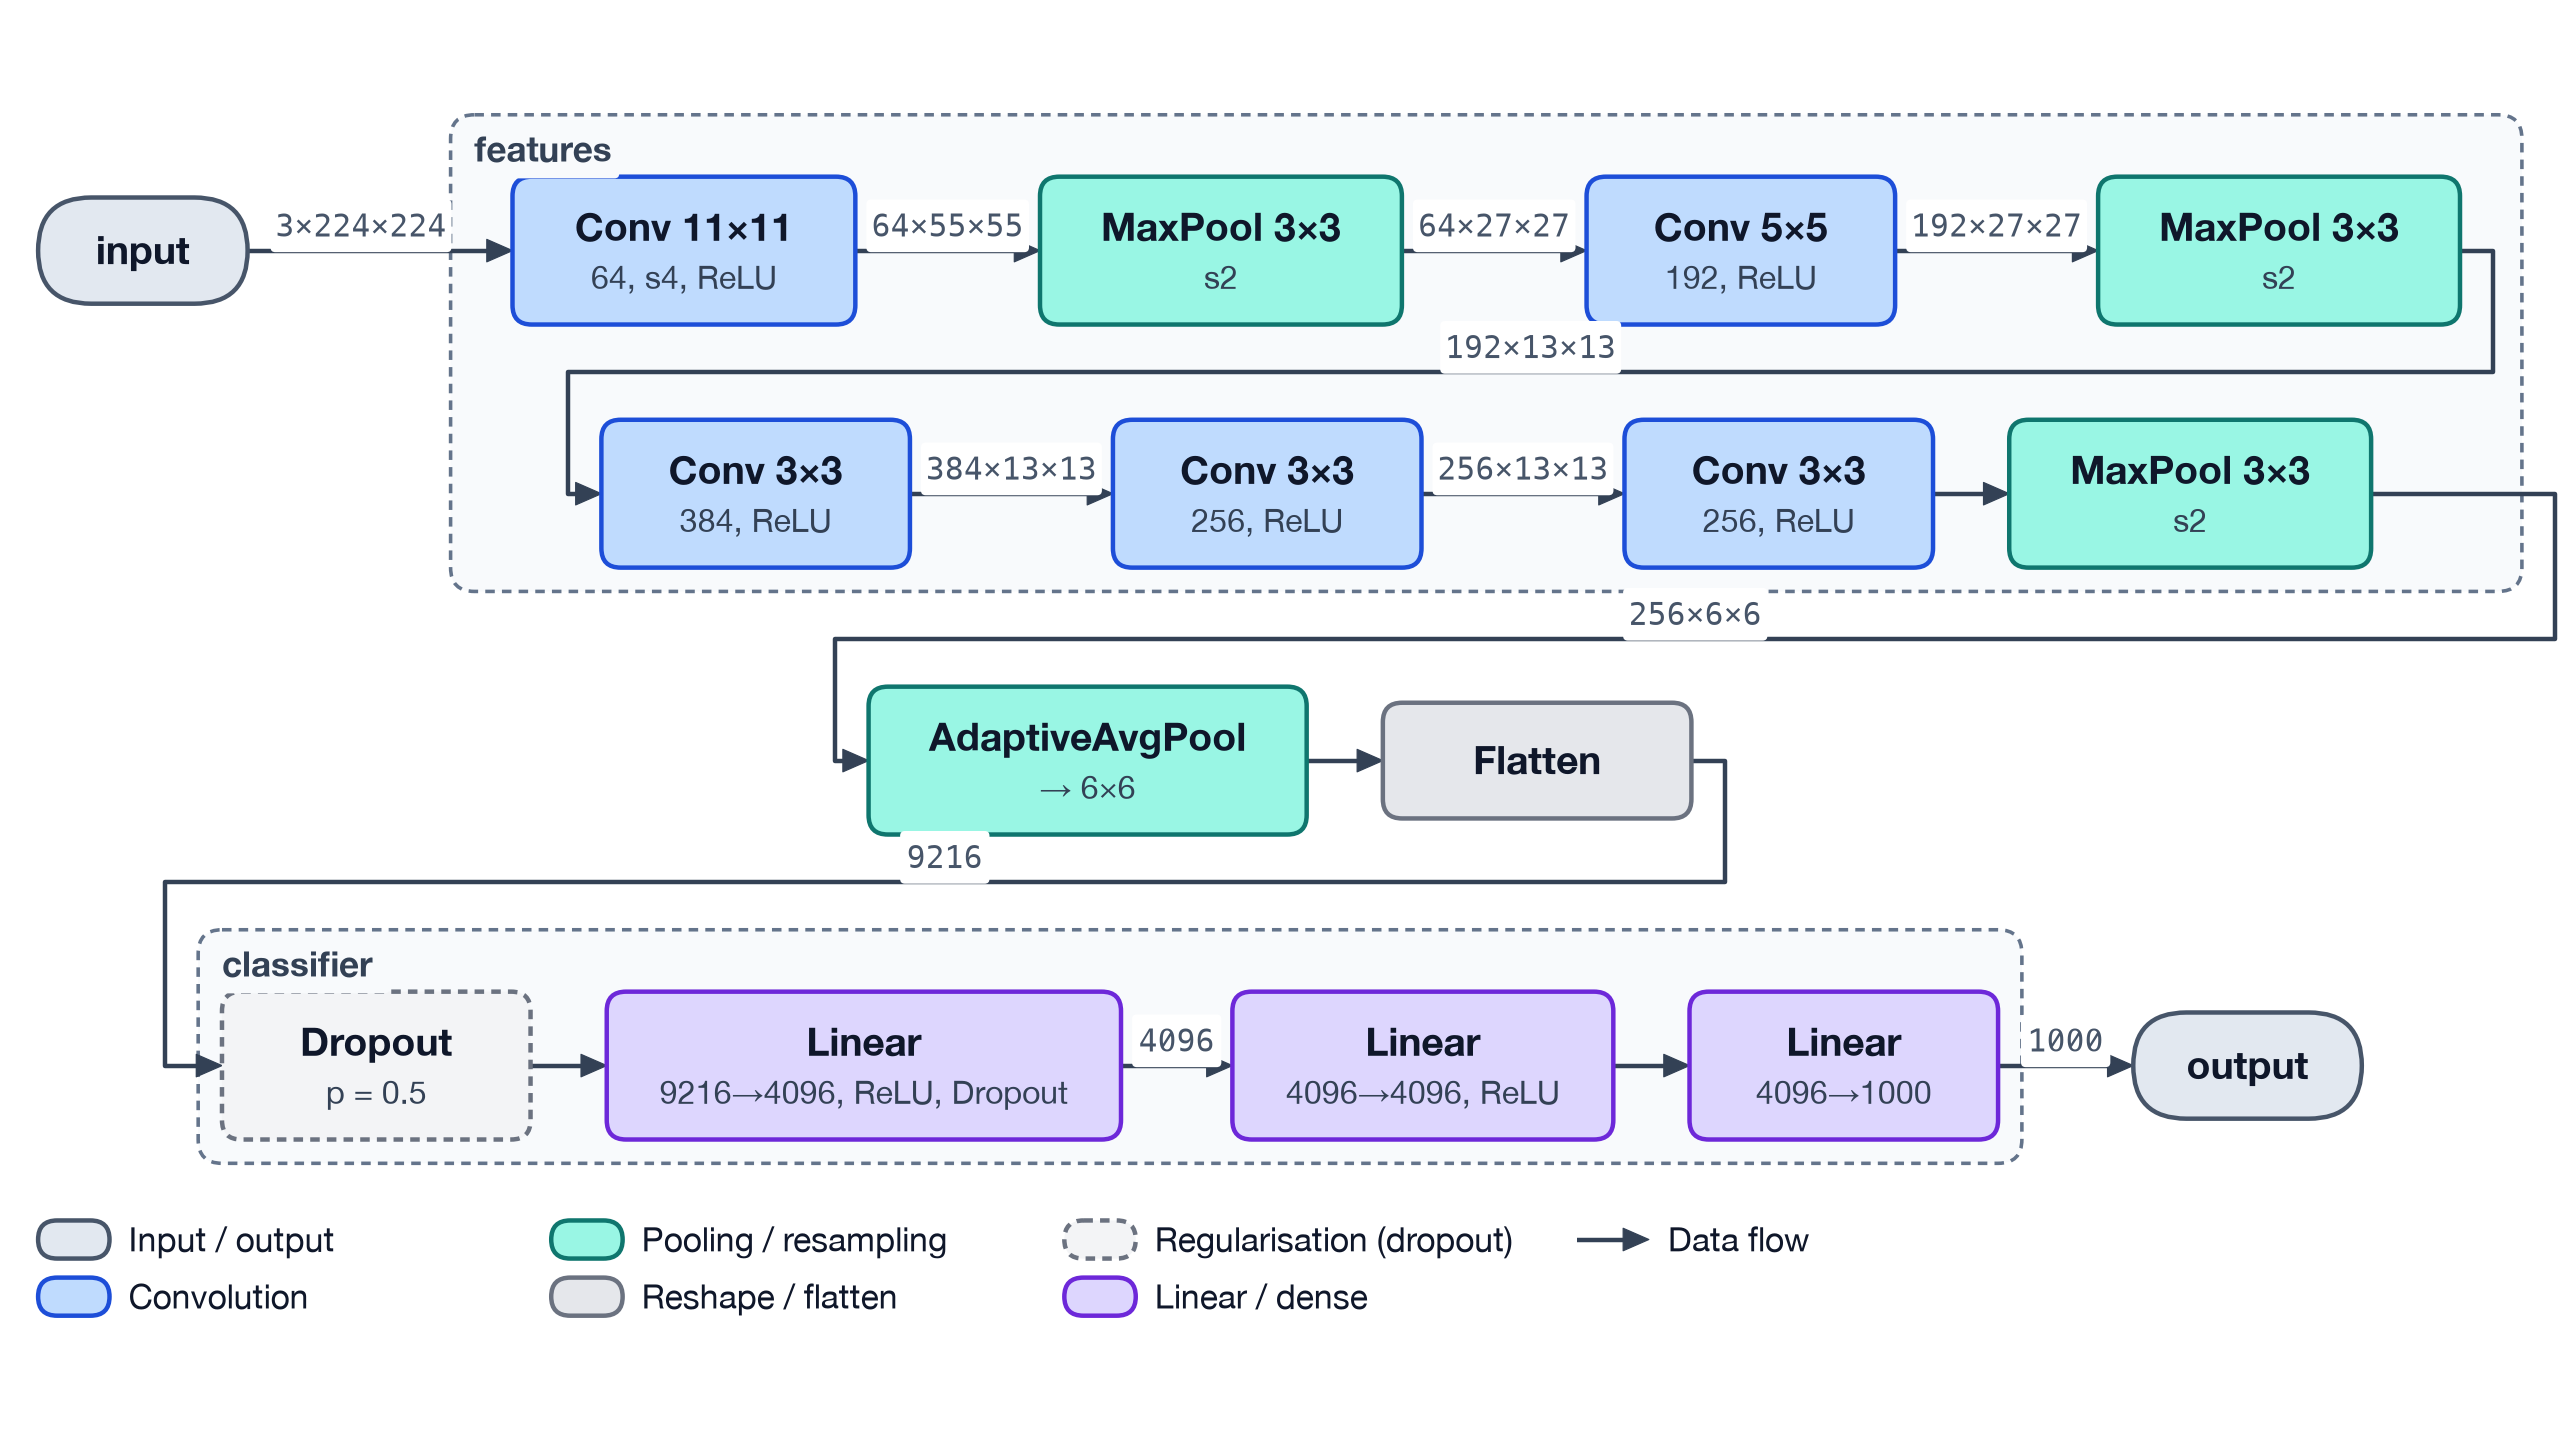

In [11]:
slide = tg.draw(model, x, fit="slide")
print(slide)
slide

For a dark slide template, with any style:

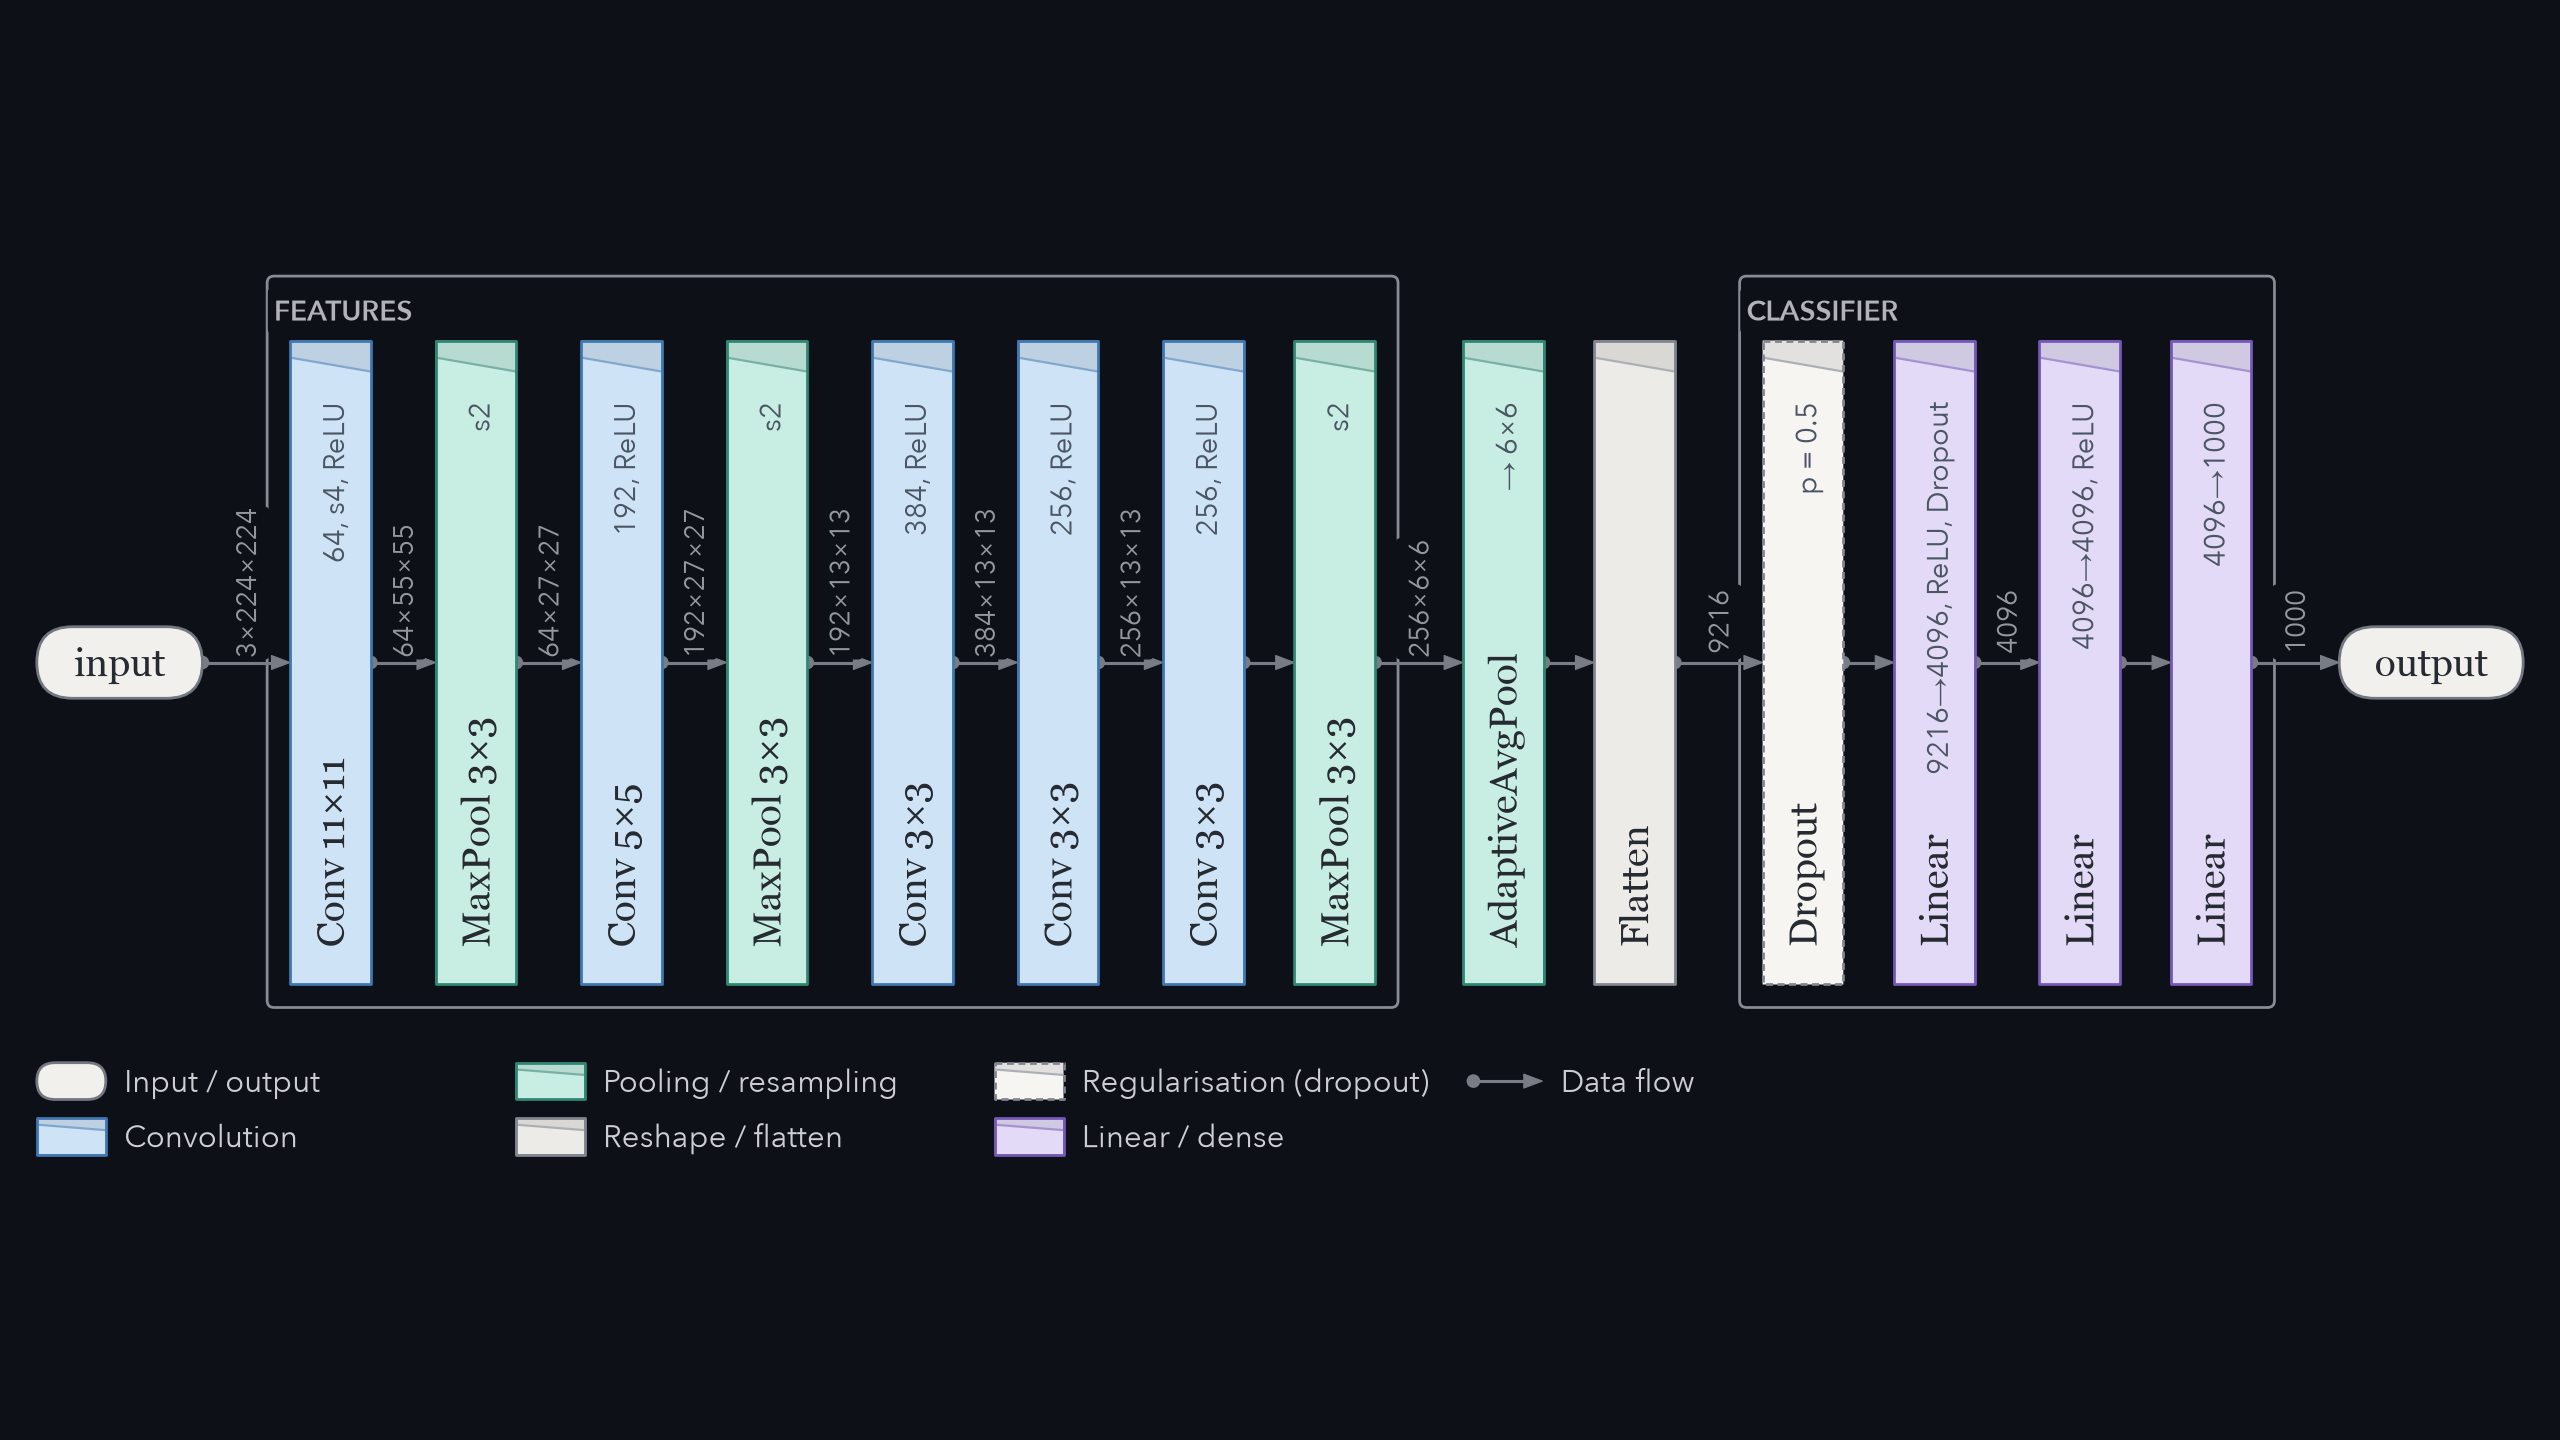

In [12]:
tg.draw(model, x, fit="slide", style="origami", variant="dark")

## In a paper

`width=` lays the figure out for the width it will have in a document, keeping the text at
its true size (box names 9 pt), and saves it exactly that wide: in LaTeX,
`\includegraphics{alexnet.pdf}` without scaling. A two-column paper's full width is about
7 in; a column about 3.5 in, where the stage level keeps the text at 9 pt. The figure says
how large its text is, and warns when it has to shrink below 7 pt.

<tensorgami.Figure 'AlexNet' 672×672 px, style 'default', 7 in wide, box names 9 pt>


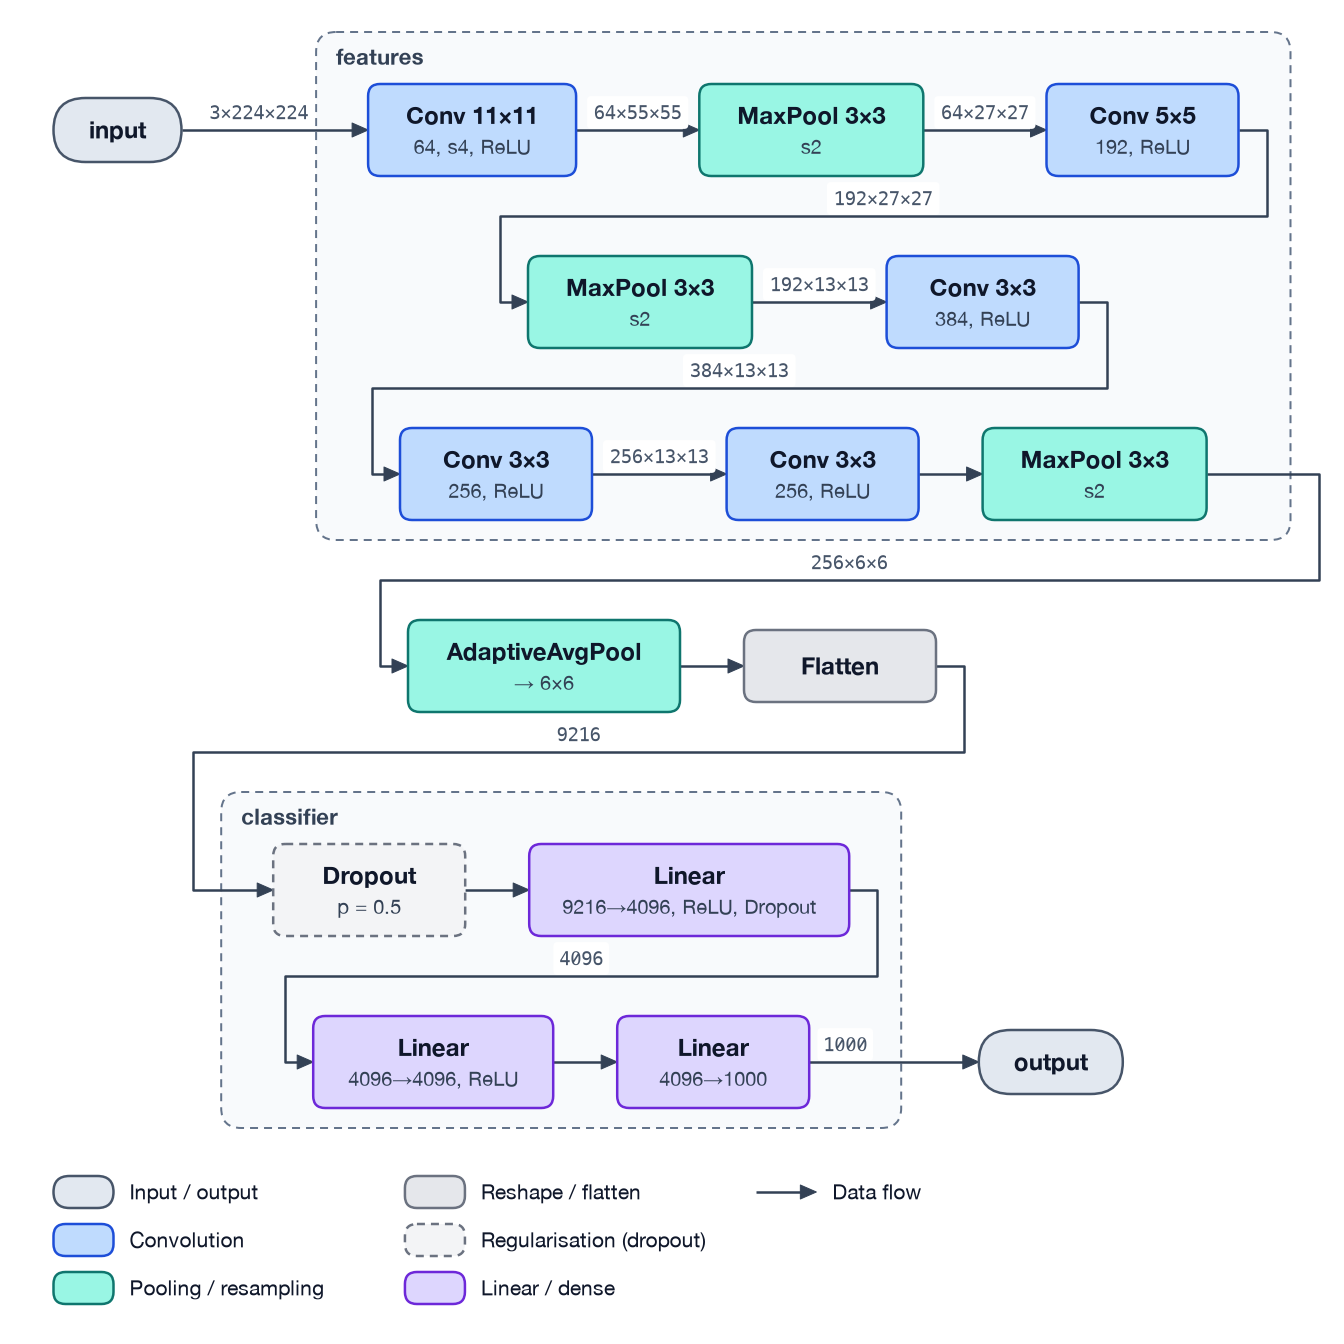

In [13]:
paper = tg.draw(model, x, width="7in")
print(paper)
paper

<tensorgami.Figure 'AlexNet' 336×342 px, style 'default', 3.5 in wide, box names 9 pt>


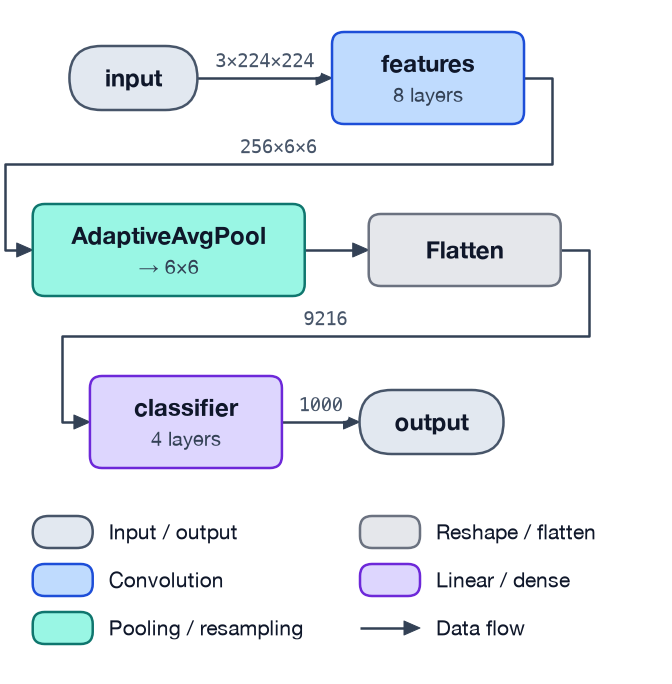

In [14]:
column = tg.draw(model, x, width="3.5in", level="stages")
print(column)
column

## Animation

`fig.animate()` lights the figure up as the model runs: layer after layer in the order data
reaches them (parallel branches together, a merge after all its inputs, a block folded ×N
once per pass), then the whole model. What has not run yet is faded, what runs now is
highlighted, and between two steps the data travels: a pulse runs along each wire into the
next layer, and the wire's tensor shape appears as it arrives. It plays here;
`anim.save("alexnet.gif")` writes a looping GIF (`.mp4` with ffmpeg installed), and
`anim.save_frames(folder)` one image per step, for a slide that builds up step by step
(`animate(flow=False)`: the steps alone, no travelling).

<tensorgami.Animation 'AlexNet' 17 steps, 107 frames, 17.4 s>


<tensorgami.Animation 'AlexNet' 17 steps, 107 frames, 17.4 s>
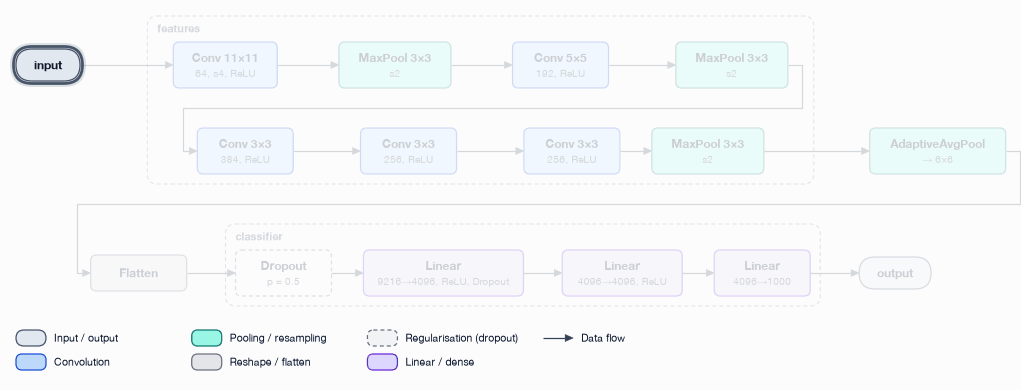

In [15]:
anim = tg.draw(model, x).animate()
print(anim)
anim

## Saving

The format follows the suffix: `.png` (choose the `dpi`), `.svg`, `.pdf`, `.jpg`, `.tif`.
Here into a temporary folder, so the example writes nothing next to the notebook.

In [16]:
import tempfile
from pathlib import Path

folder = Path(tempfile.mkdtemp())  # a scratch folder here; any path of yours works
fig = tg.draw(model, x)
for path in (fig.save(folder / "alexnet.png", dpi=300), fig.save(folder / "alexnet.svg")):
    print(f"{path.name}: {path.stat().st_size / 1024:.0f} kB")

alexnet.png: 230 kB
alexnet.svg: 20 kB


Tensorgami figures can be panels of your own matplotlib layouts:

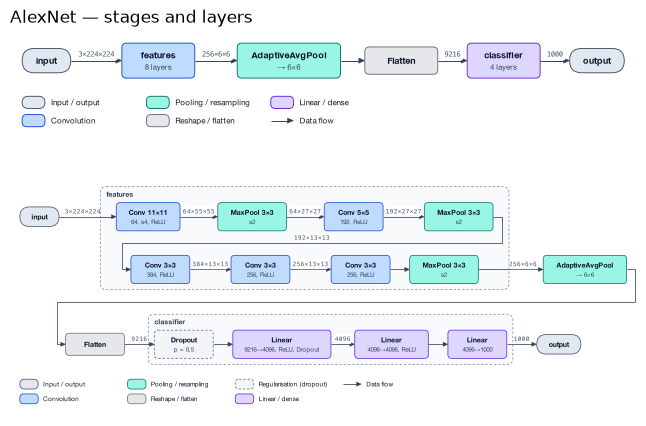

In [17]:
import matplotlib.pyplot as plt

stages, layers = tg.draw(model, x, level="stages"), tg.draw(model, x)
heights = [f.size[1] / f.size[0] for f in (stages, layers)]  # each panel keeps its proportions
panels, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5), height_ratios=heights)
stages.draw_on(top)
layers.draw_on(bottom)
top.set_title("AlexNet — stages and layers", loc="left")
plt.show()